# Wing-box modeled as a multi-domain assembly

This example computes the first buckling load of a wing-box under a tip force and compares it with the Abaqus model of Elalfy, De Breuker and Castro. It studies the convergence with the number of terms for the two connection methods, and adds blade stringers to the box.

`create_wingbox` builds the rectangular, untapered wing-box of Elalfy, De Breuker and Castro, case High-AR-t5 (their Tables 1 and 2, p. 7). Skins, spars, ribs and optionally blade stringers are all plate domains, in the groups `'skin_top'`, `'skin_bot'`, `'spar'`, `'rib'` and `'stringer'`. The argument `models` selects the model of each group, by the keys `'skin'`, `'spar'`, `'stringer'` and `'rib'`. By default the skins and the ribs are `'plate_clpt_donnell'`, with the von Kármán strains, and the spars and the stringers `'plate_clpt_gl'`, with the Green-Lagrange strains, because they are loaded in their own plane, see the last section. They are connected with penalty stiffnesses, `conn_method='penalty'`, or exactly, `conn_method='null-space'`, see `panels.multidomain.wingbox` and [Exact connections with the null-space method](../multidomain_null_space.rst). The wing-box is clamped at the root and loaded by a vertical force at the tip. The ribs are connected to the skins with `'BFxcte'` and to the spars with `'BFxycte'` (`rib_spar=True`, the default). The stringers pass through the ribs without a connection.

`wingbox_tip_force_lb` runs the linear buckling analysis. The pre-buckling state is the linear static solution under a unit tip force, solved with `structsolve.solve`, which removes the null rows and columns of the clamped root. That state gives the geometric stiffness matrix of `MultiDomain.calc_kG`, and the load multipliers of $(\boldsymbol{K}_C + \lambda \boldsymbol{K}_G)\boldsymbol{c} = \boldsymbol{0}$ are the buckling tip forces in N.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from panels.multidomain import wingbox_tip_force_lb


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def plot_group(md, c, group, ax, title=''):
    """Contour of w on the domains of ``group``, spanwise coordinate along
    the horizontal axis"""
    panels = [p for p in md.panels if p.group == group]
    res = md.uvw(c, group, gridx=20, gridy=10)
    vmax = max(np.abs(f).max() for f in res['w'])
    levels = np.linspace(-vmax, vmax, 31)
    for p, x, y, f in zip(panels, res['x'], res['y'], res['w']):
        ax.contourf(x + p.x0, y + p.y0, f, levels=levels, cmap='coolwarm')
    ax.set_xlabel('spanwise $x$ (m)')
    ax.set_ylabel('chordwise $y$ (m)')
    ax.set_title(title)

## Wing-box without stringers

Without stringers the wing-box has 9 bays and 45 domains. Its first buckling mode is a local buckling of the upper skin of the root bay, in compression. The first buckling load of the Abaqus model of Elalfy et al. is 173.11 N (Table 3, p. 8). The test case uses skins of $12 \times 12$ terms, spars of $12 \times 7$ and ribs of $6 \times 8$, 13608 Ritz constants, with the null-space method.

45 domains, 13608 Ritz constants
first buckling tip forces: [176.44 184.76 202.78 210.15] N


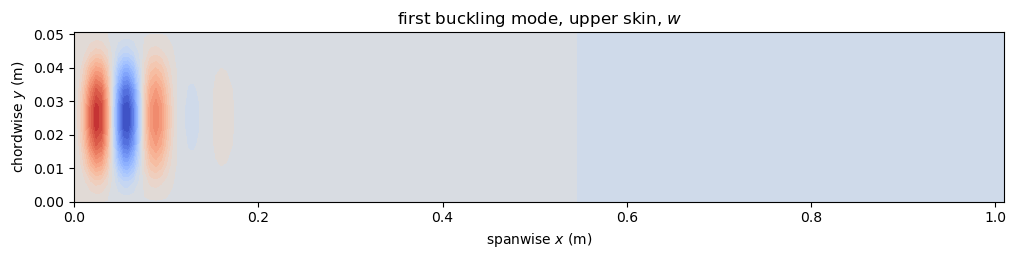

In [2]:
ABAQUS = 173.11
terms = dict(skin=(12, 12), spar=(12, 7), rib=(6, 8))
md, c, eigvals, eigvecs = wingbox_tip_force_lb(num_eigvalues=4,
                                               conn_method='null-space',
                                               terms=terms)
print('%d domains, %d Ritz constants' % (len(md.panels), md.get_size()))
print('first buckling tip forces: %s N' % np.round(eigvals[:4], 2))
fig, ax = plt.subplots(figsize=(12, 2.2))
plot_group(md, eigvecs[:, 0], 'skin_top', ax,
           'first buckling mode, upper skin, $w$')
plt.show()

## Convergence with the number of terms

The first buckling load against the number of terms $(m, n)$ of the skins, spars and ribs. The defaults of `create_wingbox` are the first row.

In [3]:
ROWS = [((8, 8), (8, 5), (4, 6)), ((10, 10), (10, 6), (5, 7)),
        ((12, 12), (12, 7), (6, 8)), ((14, 14), (14, 8), (7, 9)),
        ((16, 16), (16, 9), (8, 10))]
conv = []
for skin, spar, rib in ROWS:
    row = [skin, spar, rib]
    for method in ('null-space', 'penalty'):
        md_, c_, ev, _ = wingbox_tip_force_lb(
            num_eigvalues=4, conn_method=method,
            terms=dict(skin=skin, spar=spar, rib=rib))
        row.append(ev[0])
    row.insert(3, md_.get_size())
    conv.append(row)
    print('skins %s, spars %s, ribs %s: %d Ritz constants, null-space '
          '%.2f N, penalty %.2f N' % tuple(row))
lines = ['| skins | spars | ribs | Ritz constants | null-space (N) | penalty (N) |',
         '|---|---|---|---|---|---|']
for skin, spar, rib, size, ns, pen in conv:
    lines.append('| %d x %d | %d x %d | %d x %d | %d | %.2f | %.2f |'
                 % (*skin, *spar, *rib, size, ns, pen))
display(Markdown('\n'.join(lines)))

skins (8, 8), spars (8, 5), ribs (4, 6): 6264 Ritz constants, null-space 190.41 N, penalty 172.78 N


skins (10, 10), spars (10, 6), ribs (5, 7): 9585 Ritz constants, null-space 177.74 N, penalty 162.75 N


skins (12, 12), spars (12, 7), ribs (6, 8): 13608 Ritz constants, null-space 176.44 N, penalty 161.85 N


skins (14, 14), spars (14, 8), ribs (7, 9): 18333 Ritz constants, null-space 176.48 N, penalty 161.86 N


skins (16, 16), spars (16, 9), ribs (8, 10): 23760 Ritz constants, null-space 176.46 N, penalty 161.85 N


| skins | spars | ribs | Ritz constants | null-space (N) | penalty (N) |
|---|---|---|---|---|---|
| 8 x 8 | 8 x 5 | 4 x 6 | 6264 | 190.41 | 172.78 |
| 10 x 10 | 10 x 6 | 5 x 7 | 9585 | 177.74 | 162.75 |
| 12 x 12 | 12 x 7 | 6 x 8 | 13608 | 176.44 | 161.85 |
| 14 x 14 | 14 x 8 | 7 x 9 | 18333 | 176.48 | 161.86 |
| 16 x 16 | 16 x 9 | 8 x 10 | 23760 | 176.46 | 161.85 |

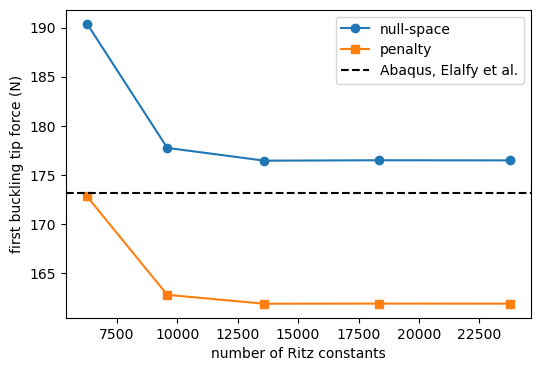

In [4]:
sizes = [r[3] for r in conv]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sizes, [r[4] for r in conv], 'o-', label='null-space')
ax.plot(sizes, [r[5] for r in conv], 's-', label='penalty')
ax.axhline(ABAQUS, color='k', ls='--', label='Abaqus, Elalfy et al.')
ax.set_xlabel('number of Ritz constants')
ax.set_ylabel('first buckling tip force (N)')
ax.legend()
plt.show()

With the null-space method the load converges from above, to a value about 2% above Abaqus. With the default penalty constants it converges to a value 6.5% below Abaqus: the default penalty constants of `calc_kt_kr` leave some relative motion at the joints. The default model, with penalty connections and 6264 Ritz constants, lies close to Abaqus only because the errors of the number of terms and of the penalty constants offset each other.

The reference value of every row is the Abaqus result of Elalfy et al., Table 3.

In [5]:
results_table([
    ('null-space, 13608 Ritz constants (N)', eigvals[0], ABAQUS,
     'Elalfy et al., Abaqus, Table 3'),
    ('null-space, %d Ritz constants (N)' % conv[-1][3], conv[-1][4], ABAQUS,
     'Elalfy et al., Abaqus, Table 3'),
    ('penalty, %d Ritz constants (N)' % conv[-1][3], conv[-1][5], ABAQUS,
     'Elalfy et al., Abaqus, Table 3'),
])

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| null-space, 13608 Ritz constants (N) | 176.435 | 173.11 | +1.92e-02 | Elalfy et al., Abaqus, Table 3 |
| null-space, 23760 Ritz constants (N) | 176.465 | 173.11 | +1.94e-02 | Elalfy et al., Abaqus, Table 3 |
| penalty, 23760 Ritz constants (N) | 161.853 | 173.11 | -6.50e-02 | Elalfy et al., Abaqus, Table 3 |

## Wing-box with blade stringers

The blade stringers are added with `nstr`, the number of stringers per skin, which also splits the skins into `nstr + 1` strips. With 4 stringers per skin, height `hs` = 3 mm and thickness `ts` = 1.5 mm, there are 225 domains. With the default terms and penalty connections the first buckling mode involves the upper skin and its stringers in the two bays next to the root, with a global bending part. This configuration is not one of the paper, and no reference value is available.

225 domains, 19872 Ritz constants
first buckling tip force: 518.0 N


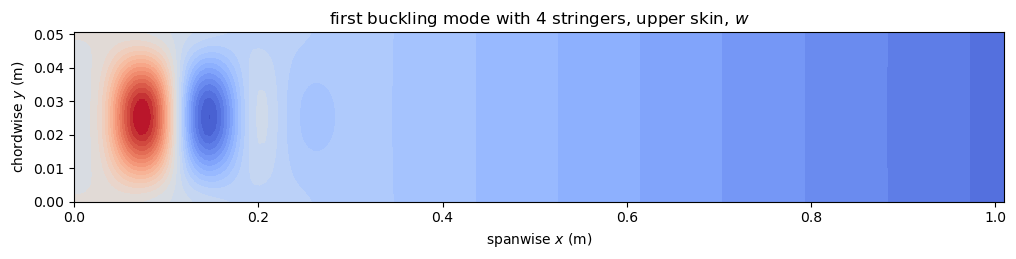

In [6]:
md, c, eigvals, eigvecs = wingbox_tip_force_lb(nstr=4, hs=3.e-3, ts=1.5e-3)
print('%d domains, %d Ritz constants' % (len(md.panels), md.get_size()))
print('first buckling tip force: %.1f N' % eigvals[0])
fig, ax = plt.subplots(figsize=(12, 2.2))
plot_group(md, eigvecs[:, 0], 'skin_top', ax,
           'first buckling mode with 4 stringers, upper skin, $w$')
plt.show()

## Spars with von Kármán or Green-Lagrange strains

The spars are plates loaded in their own plane. When the box bends under the tip force, the web of each spar carries the bending stress resultant $N_{xx}$ of the box, which varies linearly over the height of the spar: tension in the upper half, compression in the lower half. The deflection of the box is the in-plane displacement $v$ of the spars. The second variation of the membrane energy with the Green-Lagrange strain $\varepsilon_{xx} = u_{,x} + \frac{1}{2}(u_{,x}^2 + v_{,x}^2 + w_{,x}^2)$ of `'plate_clpt_gl'` has the term $N_{xx} \, \delta v_{,x}^2$, which the von Kármán strain $\varepsilon_{xx} = u_{,x} + \frac{1}{2} w_{,x}^2$ of `'plate_clpt_donnell'` omits. The same term makes the stringers `'plate_clpt_gl'`: a stringer lies wholly on one side of the neutral axis and its load destabilizes its in-plane bending.

For a spar the term is expected to be small. On a deflection $v$ that is uniform over the height of the spar, its work is $\frac{1}{2} v_{,x}^2 \int N_{xx} \, \mathrm{d}y$, and the resultant of $N_{xx}$ over the height of the web is zero in pure bending. Only the part of $v$ that varies over the height contributes.

The first buckling tip force is computed with `models=dict(spar='plate_clpt_donnell')` and with `models=dict(spar='plate_clpt_gl')` (the default), for the cases of this example: without stringers with the default terms and penalty connections, and with the converged terms of the first section and the null-space method; with 2 and 4 stringers per skin with the default terms. For each case with `'plate_clpt_gl'` spars the cell also prints the largest in-plane displacement $v$ of the spars in the first mode, relative to the largest $w$ of the upper skin, and how much $v$ varies over the height of the spars, relative to its largest value.

In [7]:
CASES = [
    ('no stringers, default terms, penalty', dict()),
    ('no stringers, 13608 Ritz constants, null-space',
     dict(conn_method='null-space', terms=terms)),
    ('2 stringers, default terms, penalty', dict(nstr=2)),
    ('4 stringers, default terms, penalty', dict(nstr=4, hs=3.e-3, ts=1.5e-3)),
]
spar_rows = []
for name, kw in CASES:
    res = {}
    for spar_model in ('plate_clpt_donnell', 'plate_clpt_gl'):
        md_, c_, ev, evec = wingbox_tip_force_lb(num_eigvalues=4,
                models=dict(spar=spar_model), **kw)
        res[spar_model] = ev[0]
    # first mode with 'plate_clpt_gl' spars: in-plane displacement v of the
    # spars (axis 0 of the grid along their height, axis 1 along x)
    vs = [np.asarray(v) for v in md_.uvw(evec[:, 0], 'spar', gridx=30,
                                         gridy=15)['v']]
    ws = md_.uvw(evec[:, 0], 'skin_top', gridx=30, gridy=15)['w']
    vmax = max(np.abs(v).max() for v in vs)
    wmax = max(np.abs(w).max() for w in ws)
    dv = max(np.abs(v - v.mean(axis=0, keepdims=True)).max() for v in vs)
    print('%s: %d Ritz constants, spars max|v| = %.2f max|w| of the upper '
          'skin, variation of v over the height %.3f max|v|'
          % (name, md_.get_size(), vmax/wmax, dv/vmax))
    spar_rows.append((name, md_.get_size(), res['plate_clpt_donnell'],
                      res['plate_clpt_gl']))
lines = ['| case | Ritz constants | spars `plate_clpt_donnell` (N) | '
         'spars `plate_clpt_gl` (N) | relative difference |',
         '|---|---|---|---|---|']
for name, size, vk, gl in spar_rows:
    lines.append('| %s | %d | %.4f | %.4f | %+.2e |'
                 % (name, size, vk, gl, (gl - vk)/vk))
display(Markdown('\n'.join(lines)))

no stringers, default terms, penalty: 6264 Ritz constants, spars max|v| = 0.07 max|w| of the upper skin, variation of v over the height 0.002 max|v|


no stringers, 13608 Ritz constants, null-space: 13608 Ritz constants, spars max|v| = 0.12 max|w| of the upper skin, variation of v over the height 0.001 max|v|


2 stringers, default terms, penalty: 12096 Ritz constants, spars max|v| = 0.03 max|w| of the upper skin, variation of v over the height 0.005 max|v|


4 stringers, default terms, penalty: 19872 Ritz constants, spars max|v| = 0.82 max|w| of the upper skin, variation of v over the height 0.000 max|v|


| case | Ritz constants | spars `plate_clpt_donnell` (N) | spars `plate_clpt_gl` (N) | relative difference |
|---|---|---|---|---|
| no stringers, default terms, penalty | 6264 | 172.7828 | 172.7826 | -1.11e-06 |
| no stringers, 13608 Ritz constants, null-space | 13608 | 176.4354 | 176.4351 | -1.37e-06 |
| 2 stringers, default terms, penalty | 12096 | 436.0593 | 436.0549 | -1.01e-05 |
| 4 stringers, default terms, penalty | 19872 | 518.0477 | 518.0323 | -2.97e-05 |

The relative difference is that of the `'plate_clpt_gl'` spars against the `'plate_clpt_donnell'` spars. In all the cases the `'plate_clpt_gl'` spars lower the first buckling tip force by less than $10^{-4}$. Without stringers and with 2 stringers the first mode is a local buckling of the upper skin, with its stringers, near the root, and the spars hardly move in their plane. With 4 stringers the mode has a vertical deflection of the box, and $v$ of the spars is of the order of $w$ of the upper skin, but it is nearly uniform over the height of the spars, so that the bending stresses of the web do almost no work on it. The term $N_{xx} \, \delta v_{,x}^2$ of the spars matters only for a mode in which the spar webs bend in their own plane with a deflection that varies over their height, which none of these first modes does. The static deflection is the same with both models, whose linear stiffness is the same.

## References

1. M. H. Elalfy, R. De Breuker and S. G. P. Castro, "Beam-like models for the post-buckling behaviour of wingbox structures". Preprint, Delft University of Technology (undated, 29 pages): Tables 1 to 3, pp. 6-8.